## Exercise 1: (Order Matters) Non-commuting gates

In classical programming, the order of independent operations often doesn't matter. In quantum computing, gates are matrices, and matrix multiplication is non-commutative. Let's visualize this geometric reality on the Bloch sphere.

### Tasks: 

1. Create two 1-qubit circuits initialized to $|0\rangle$: 
    - Circuit 1: Apply an H gate, then an S gate. 
    - Circuit 2: Apply an S gate, then an H gate.
    
2. Use Qiskit's `plot_bloch_multivector` to plot the final state of both circuits.

3. Some quantum gates do commute with each other. Can you find an example of two commuting gates?

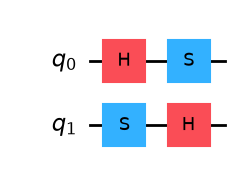

In [4]:
### Answer here
from qiskit.circuit import QuantumCircuit

qc1 = QuantumCircuit(2)

qc1.h(0)
qc1.s(0)
qc1.s(1)
qc1.h(1)
qc1.draw("mpl")


[0.5+0.j  0. +0.5j 0.5+0.j  0. +0.5j]
{np.str_('00'): np.float64(0.2499999999999999), np.str_('01'): np.float64(0.2499999999999999), np.str_('10'): np.float64(0.2499999999999999), np.str_('11'): np.float64(0.2499999999999999)}


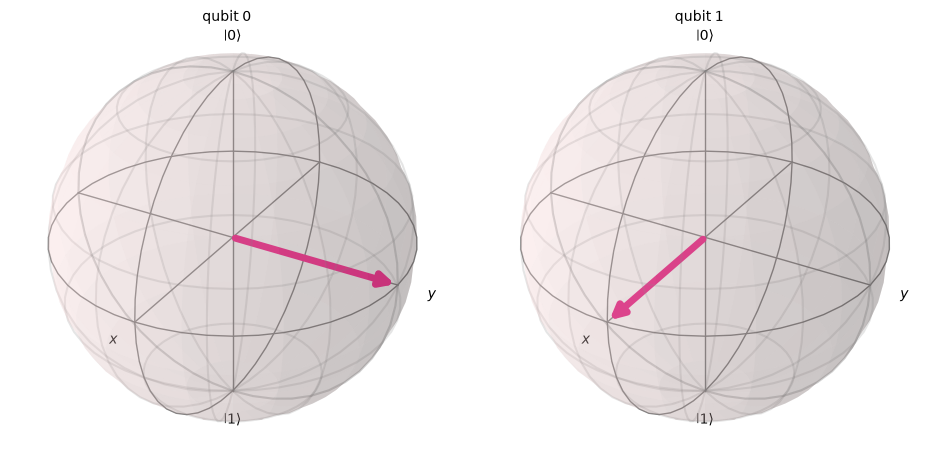

In [5]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector

state = Statevector.from_instruction(qc1)

print(state.data)
print(state.probabilities_dict())

plot_bloch_multivector(state)

## Exercise 2: The Phase Kickback

We know the CNOT gate flips the target qubit if the control qubit is $|1\rangle$. But what happens if the target qubit is already in a superposition? 

#### Tasks:

1.  Initialize a 2-qubit circuit. 

2.  Put the control qubit (qubit 0) into the $|+\rangle$ state and the target qubit (qubit 1) into the $|-\rangle$ state. Apply a CNOT gate (qc.cx(0, 1)). 

3.  Visualize the final statevector or simulate the state.

Questions to ponder:

* Q1: What changed? Did the target qubit flip, or did something happen to the control qubit? 
* Q2: This phenomenon is called Phase Kickback. Looking at the math of how CNOT acts on $|+-\rangle$, can you explain why the phase shifted where it did?

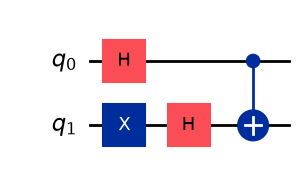

In [6]:
### Answer here
from qiskit.circuit import QuantumCircuit

qc = QuantumCircuit(2)
#Control qubit
qc.h(0)
#Target qubit
qc.x(1)
qc.h(1)
#Apply cnot gate
qc.cx(0,1)

qc.draw("mpl")


Final statevector:
Statevector([0.+0.j, 0.+0.j, 1.+0.j, 0.+0.j],
            dims=(2, 2))
Probabilities:
{np.str_('10'): np.float64(1.0)}
{np.str_('00'): np.float64(0.2499999999999999),
 np.str_('01'): np.float64(0.2499999999999999),
 np.str_('10'): np.float64(0.2499999999999999),
 np.str_('11'): np.float64(0.2499999999999999)}


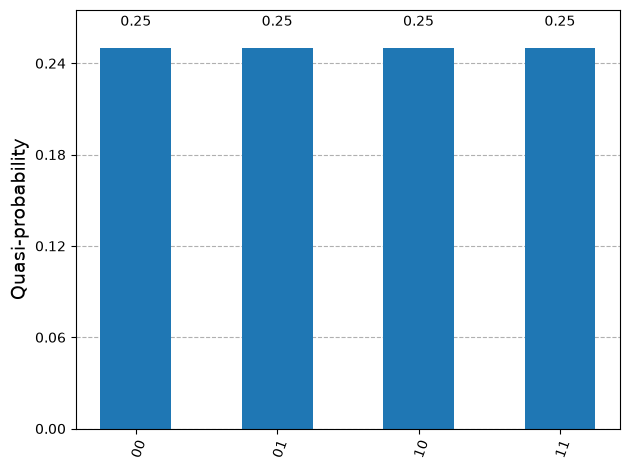

In [9]:
from qiskit.visualization import plot_histogram
import pprint

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
sv = Statevector.from_instruction(qc)
print("Final statevector:")
print(sv)
print("Probabilities:")
print(sv.probabilities_dict())
pprint.pp(state.probabilities_dict())
plot_histogram(state.probabilities_dict())


The control qubit changed from |+> to |-> whereas the target qubit remained |->.

The target qubit did not undergo a net state change.
The control qubit acquired a relative phase of \(-1\) between its two computational basis components.
The fundamental principle:

When the target of a controlled operation is an eigenstate of the operation, its eigenvalue becomes a relative phase on the control qubit.

This principle is not restricted to CNOT. It is fundamental to:
-Quantum phase estimation.
-Quantum Fourier transform algorithms.
 Deutsch-Jozsa algorithm.
-Quantum algorithm design involving controlled-unitary operations.

## Exercise 3: SWAP gate from scratch

Qiskit has a built-in SWAP gate (qc.swap(0, 1)), which exchanges the states of two qubits. However, hardware architectures often only support CNOTs and single-qubit gates.

Tasks: 

1.  Initialize a 2-qubit circuit to the state $|10\rangle$ (qubit 0 is $|1\rangle$, qubit 1 is $|0\rangle$). 

2.  Using only three CNOT gates (and no other gates), see if you can manipulate the circuit so that the final state becomes $|01\rangle$.

3.  Qiskit has methods to decompose some gates into simpler consituent gates. See if you can find out how to decompose the SWAP gate using Qiskit's inbuilt methods as a way of 'cheating' for this question. 


Questions to ponder: 

* Q1: Does your 3-CNOT circuit work if you change the initial state to $|01\rangle$? What about $|++\rangle$?

* Q2: Why is being able to decompose a SWAP gate into CNOTs incredibly important for real, physical quantum computers?

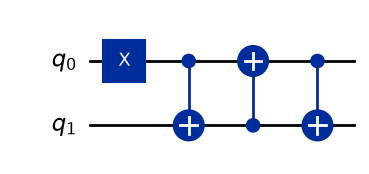

In [10]:
### Answer here
from qiskit.circuit import QuantumCircuit

qc = QuantumCircuit(2)
qc.x(0)
qc.cx(0,1)
qc.cx(1,0)
qc.cx(0,1)
qc.draw("mpl")

In [11]:
print("Final circuit:")
print(qc.draw())

# Calculate final statevector
state = Statevector.from_instruction(qc)

print("Final statevector:")
print(state)

print("Final probabilities:")
print(state.probabilities_dict())


Final circuit:
     ┌───┐     ┌───┐     
q_0: ┤ X ├──■──┤ X ├──■──
     └───┘┌─┴─┐└─┬─┘┌─┴─┐
q_1: ─────┤ X ├──■──┤ X ├
          └───┘     └───┘
Final statevector:
Statevector([0.+0.j, 0.+0.j, 1.+0.j, 0.+0.j],
            dims=(2, 2))
Final probabilities:
{np.str_('10'): np.float64(1.0)}


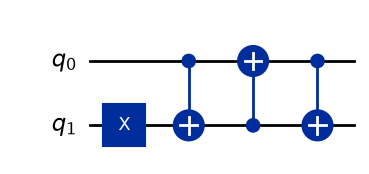

In [14]:
from qiskit.circuit import QuantumCircuit

qc1 = QuantumCircuit(2)
qc1.x(1)
qc1.cx(0,1)
qc1.cx(1,0)
qc1.cx(0,1)
qc1.draw("mpl")

In [15]:
print("Final circuit:")
print(qc.draw())

# Calculate final statevector
sv1 = Statevector.from_instruction(qc1)

print("Final statevector:")
print(state)

print("Final probabilities:")
print(state.probabilities_dict())

Final circuit:
               ┌───┐     
q_0: ───────■──┤ X ├──■──
     ┌───┐┌─┴─┐└─┬─┘┌─┴─┐
q_1: ┤ X ├┤ X ├──■──┤ X ├
     └───┘└───┘     └───┘
Final statevector:
Statevector([0.+0.j, 1.+0.j, 0.+0.j, 0.+0.j],
            dims=(2, 2))
Final probabilities:
{np.str_('01'): np.float64(1.0)}


In [17]:
#Does the 3-CNOT circuit work if you change the initial state to  |01⟩? What about  |++⟩?
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# Test 1: Initial state |01>
qc1 = QuantumCircuit(2)
qc1.x(1)

qc1.cx(0, 1)
qc1.cx(1, 0)
qc1.cx(0, 1)

sv1 = Statevector.from_instruction(qc1)

print("Initial |01>")
print("Final state:", sv1)
print("Probabilities:", sv1.probabilities_dict())


# Test 2: Initial state |++>
qc2 = QuantumCircuit(2)

qc2.h(0)
qc2.h(1)

qc2.cx(0, 1)
qc2.cx(1, 0)
qc2.cx(0, 1)

sv2 = Statevector.from_instruction(qc2)

print("\nInitial |++>")
print("Final state:", sv2)
print("Probabilities:", sv2.probabilities_dict())


Initial |01>
Final state: Statevector([0.+0.j, 1.+0.j, 0.+0.j, 0.+0.j],
            dims=(2, 2))
Probabilities: {np.str_('01'): np.float64(1.0)}

Initial |++>
Final state: Statevector([0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j],
            dims=(2, 2))
Probabilities: {np.str_('00'): np.float64(0.2499999999999999), np.str_('01'): np.float64(0.2499999999999999), np.str_('10'): np.float64(0.2499999999999999), np.str_('11'): np.float64(0.2499999999999999)}


### Exercise 4: Global vs Relative phase

Quantum simulators let us look directly at statevectors, but real quantum computers can only give us measurement counts. Let's see how phases behave under the hood versus what we can actually observe.

Tasks: 

1. Create two separate 1-qubit circuits: 

    - Circuit A: Apply an X gate, then a Z gate to qubit 0. 
    - Circuit B: Apply a Z gate, then an X gate to qubit 0.
    
2. Print the final statevector for both circuits. Notice the difference. 

3. Now, add a measurement gate (qc.measure_all()) to both circuits and run them on a simulator to get the outcome counts (histogram). 

Questions to ponder: 

- Q1: Look at the statevectors. One should be $|1\rangle$ and the other $-|1\rangle$. What is the mathematical name for this negative sign out front?

- Q2: Look at the measurement histograms. Do the measurement outcomes differ between Circuit A and Circuit B? 

- Q3: Based on this, why do we say a global phase is physically unobservable, while a relative phase (like the one in $|-\rangle = \frac{|0\rangle - |1\rangle}{\sqrt{2}}$) is observable?

In [37]:
### Answer here
#CircuitA
qcA = QuantumCircuit(1)
qcA.x(0)
qcA.z(0)
svA = Statevector.from_instruction(qcA)


print("Final state:", svA)
print("Probabilities:", svA.probabilities_dict())

#CircuitB
qcB=QuantumCircuit(1)
qcB.z(0)
qcB.x(0)

svB = Statevector.from_instruction(qcB)


print("Final state:", svB)
print("Probabilities:", svB.probabilities_dict())
# The negative sign refers to the global phase factor which is unobservable

Final state: Statevector([ 0.+0.j, -1.+0.j],
            dims=(2,))
Probabilities: {np.str_('1'): np.float64(1.0)}
Final state: Statevector([0.+0.j, 1.+0.j],
            dims=(2,))
Probabilities: {np.str_('1'): np.float64(1.0)}


{'1 1 1': 1024}


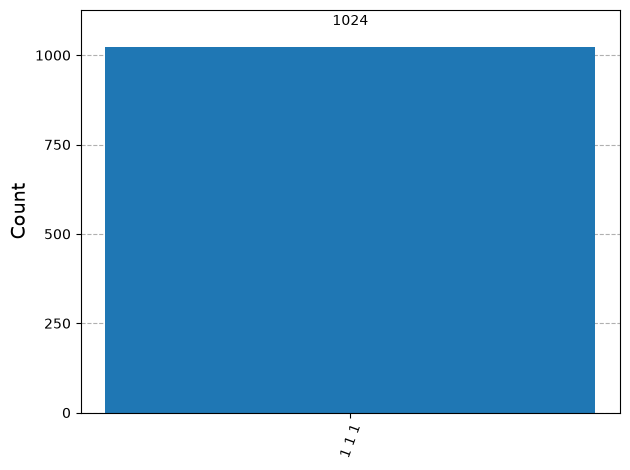

In [34]:
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

qcA.measure_all()
qcB.measure_all()
# 4. Instantiate hardware
simulator = AerSimulator()

# 5. Run the circuit on the (virtual) hardware
resultA = simulator.run(qcA).result()
resultB = simulator.run(qcA).result()
countsA = resultA.get_counts()
countsB = resultB.get_counts()



print(countsA)
plot_histogram(countsA)



{'1 1 1': 1024}


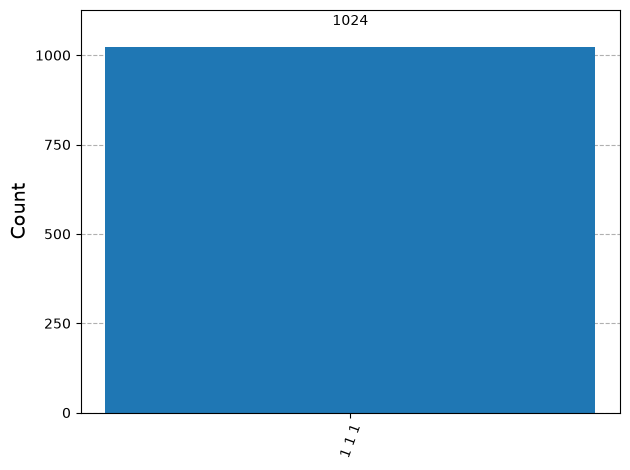

In [35]:
print(countsB)
plot_histogram(countsB)


In [39]:
#Relative phase is observable through interference
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# Circuit for |+>
qc_plus = QuantumCircuit(1)
qc_plus.h(0)
qc_plus.h(0)

sv_plus = Statevector.from_instruction(qc_plus)
print("H|+>:", sv_plus)

# Circuit for |->
qc_minus = QuantumCircuit(1)
qc_minus.x(0)
qc_minus.h(0)
qc_minus.h(0)

# Instead, construct |- > directly using X followed by H
qc_minus = QuantumCircuit(1)
qc_minus.x(0)
qc_minus.h(0)

sv_minus = Statevector.from_instruction(qc_minus)
print("H|->:", sv_minus)


H|+>: Statevector([1.+0.j, 0.+0.j],
            dims=(2,))
H|->: Statevector([ 0.70710678+0.j, -0.70710678+0.j],
            dims=(2,))


## Exercise 5: Bell state inverter

We know how to generate the Bell state $\ket{\Phi^+} = \frac{\ket{00} + \ket{11}}{\sqrt{2}}$ starting from $\ket{00}$. But can we go backward?

Tasks:

1. Create a 2-qubit circuit initialized to $\ket{00}$. Apply the gates necessary to create the $\ket{\Phi^+}$ Bell state. 

2. We want the final state of the circuit to be back at $\ket{00}$ with 100% probability. What gates must you apply to achieve this "inversion"? (You are effectively calculating the inverse of the Bell state circuit).

3. Confirm your answer in Qiskit by running a simulation (measurement or statevector).

4. Qiskit has a built in `qc.inverse()` method. Redo the exercise using this method. (You will have to create a second circuit `inverse_qc = qc.inverse()` and then do `qc.append(inverse_qc)`)

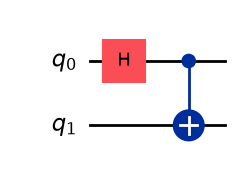

In [54]:
qc_bell = QuantumCircuit(2)
qc_bell.h(0)
qc_bell.cx(0,1)

qc_bell.draw("mpl")




In [56]:
bell_state = Statevector.from_instruction(qc_bell)
print("\nBell statevector:")
print(bell_state)

print("Bell state probabilities:")
print(bell_state.probabilities_dict())


Bell statevector:
Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))
Bell state probabilities:
{np.str_('00'): np.float64(0.4999999999999999), np.str_('11'): np.float64(0.4999999999999999)}


In [41]:
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

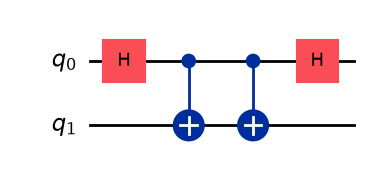

In [57]:
qc_bell.cx(0,1)
qc_bell.h(0)
qc_bell.draw("mpl")

In [58]:
# Calculate final statevector
final_state = Statevector.from_instruction(qc_bell)

print("\nFinal statevector:")
print(final_state)

print("Final probabilities:")
print(final_state.probabilities_dict())



Final statevector:
Statevector([ 1.00000000e+00+0.j, -2.23711432e-17+0.j,  0.00000000e+00+0.j,
              0.00000000e+00+0.j],
            dims=(2, 2))
Final probabilities:
{np.str_('00'): np.float64(0.9999999999999996), np.str_('01'): np.float64(5.004680467665246e-34)}


{'00': 1024}


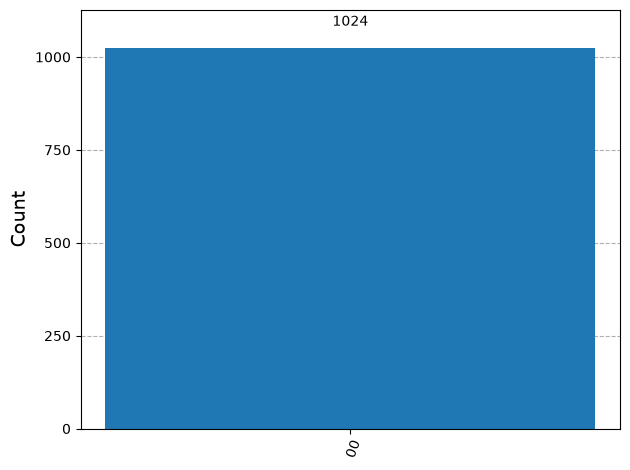

In [60]:
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
simulator = AerSimulator()
qc_bell.measure_all()
result = simulator.run(qc_bell).result()
count = result.get_counts()
print(counts)
plot_histogram(counts)

In [46]:

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

# Create a 2-qubit circuit
qc = QuantumCircuit(2)

# ---------------------------------
# Part A: Create Bell state |Phi+>
# ---------------------------------

qc.h(0)
qc.cx(0, 1)

print("Bell state preparation:")
print(qc.draw())

# Display Bell statevector
bell_state = Statevector.from_instruction(qc)

print("\nBell statevector:")
print(bell_state)

print("Bell state probabilities:")
print(bell_state.probabilities_dict())

# ---------------------------------
# Part B: Invert Bell state circuit
# ---------------------------------

qc.cx(0, 1)
qc.h(0)

print("\nCircuit after inversion:")
print(qc.draw())

# Calculate final statevector
final_state = Statevector.from_instruction(qc)

print("\nFinal statevector:")
print(final_state)

print("Final probabilities:")
print(final_state.probabilities_dict())

# ---------------------------------
# Part C: Measurement
# ---------------------------------

qc.measure_all()

simulator = AerSimulator()

compiled = transpile(qc, simulator)

result = simulator.run(
    compiled,
    shots=1024
).result()

counts = result.get_counts()

print("\nMeasurement counts:")
print(counts)


Bell state preparation:
     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘

Bell statevector:
Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))
Bell state probabilities:
{np.str_('00'): np.float64(0.4999999999999999), np.str_('11'): np.float64(0.4999999999999999)}

Circuit after inversion:
     ┌───┐          ┌───┐
q_0: ┤ H ├──■────■──┤ H ├
     └───┘┌─┴─┐┌─┴─┐└───┘
q_1: ─────┤ X ├┤ X ├─────
          └───┘└───┘     

Final statevector:
Statevector([ 1.00000000e+00+0.j, -2.23711432e-17+0.j,  0.00000000e+00+0.j,
              0.00000000e+00+0.j],
            dims=(2, 2))
Final probabilities:
{np.str_('00'): np.float64(0.9999999999999996), np.str_('01'): np.float64(5.004680467665246e-34)}

Measurement counts:
{'00': 1024}


In [61]:

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

# Step 1: Create Bell state preparation circuit
qc = QuantumCircuit(2)

qc.h(0)
qc.cx(0, 1)

print("Bell state preparation circuit:")
print(qc.draw())

# Step 2: Verify Bell state
bell_state = Statevector.from_instruction(qc)

print("\nBell statevector:")
print(bell_state)

print("Bell state probabilities:")
print(bell_state.probabilities_dict())

# Step 3: Calculate inverse circuit
inverse_qc = qc.inverse()

print("\nInverse circuit:")
print(inverse_qc.draw())

# Step 4: Append inverse circuit to original circuit
# Convert the inverse circuit into an Instruction
qc.append(inverse_qc.to_instruction(), [0, 1])

print("\nCombined circuit:")
print(qc.draw())

# Step 5: Verify final state
final_state = Statevector.from_instruction(qc)

print("\nFinal statevector:")
print(final_state)

print("Final probabilities:")
print(final_state.probabilities_dict())

# Step 6: Measure and simulate
qc.measure_all()

simulator = AerSimulator()
compiled = transpile(qc, simulator)

result = simulator.run(
    compiled, shots=1024
).result()

print("\nMeasurement counts:")
print(result.get_counts())


Bell state preparation circuit:
     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘

Bell statevector:
Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))
Bell state probabilities:
{np.str_('00'): np.float64(0.4999999999999999), np.str_('11'): np.float64(0.4999999999999999)}

Inverse circuit:
          ┌───┐
q_0: ──■──┤ H ├
     ┌─┴─┐└───┘
q_1: ┤ X ├─────
     └───┘     

Combined circuit:
     ┌───┐     ┌─────────────────┐
q_0: ┤ H ├──■──┤0                ├
     └───┘┌─┴─┐│  circuit-151_dg │
q_1: ─────┤ X ├┤1                ├
          └───┘└─────────────────┘

Final statevector:
Statevector([ 1.00000000e+00+0.j, -2.23711432e-17+0.j,  0.00000000e+00+0.j,
              0.00000000e+00+0.j],
            dims=(2, 2))
Final probabilities:
{np.str_('00'): np.float64(0.9999999999999996), np.str_('01'): np.float64(5.004680467665246e-34)}

Measurement counts:
{'00': 1024}
